# Getting started with GOOSELoc

This notebook walks through the scene table, the data loader in both heading settings,
visualization, the official evaluation and the PyTorch loader.

Install with `pip install -e ".[torch,viz]"` and download the dataset into `data/GOOSELoc` (or set `ROOT` to your download)
(sections 1 and 4 work without any download).

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

from gooseloc import GOOSELoc, evaluate, load_scenes, select
from gooseloc.eval import format_summary
from gooseloc.viz import plot_aerial, plot_sample

ROOT = None  # $GOOSELOC_ROOT, else data/GOOSELoc in the repository

## 1. The scene table

One row per scene with split, terrain, season, ground truth and the protocol fields.
It is bundled with the package.

In [2]:
scenes = load_scenes()
print(len(scenes), "scenes")
display(pd.crosstab(scenes.split, scenes.season, margins=True))
display(pd.crosstab(scenes.split, scenes.terrain, margins=True))
scenes.head(3).T

9356 scenes


season,autumn,spring,summer,winter,All
split,,,,,
dev,503,304,103,154,1064
test,390,608,532,332,1862
train,1726,1976,1341,1387,6430
All,2619,2888,1976,1873,9356


terrain,paved,unpaved,All
split,,,
dev,400,664,1064
test,900,962,1862
train,2988,3442,6430
All,4288,5068,9356


,0,1,2
scene_id,1657197590365050227,1657197593865313713,1657197597665295877
split,train,train,train
timestamp_ns,1657197590365050227,1657197593865313713,1657197597665295877
date,2022-07-07,2022-07-07,2022-07-07
season,summer,summer,summer
terrain,unpaved,unpaved,unpaved
trajectory_id,1,1,1
lat,48.075885,48.07583,48.075797
lon,11.644883,11.644875,11.644847
utm_e,696999.429,696999.091,696997.11


## 2. A sample in the north-up setting

The tile is north-aligned; the target is the vehicle pixel and the compass heading.
`camera_size` downsizes the 2448 x 1000 camera images while loading.

{'scene_id': '1657199100805494597', 'setting': 'north_up', 'gt_xy': (2,), 'gt_heading_deg': (), 'tile_rotation_deg': (), 'gt_xy_north_up': (2,), 'heading_deg': (), 'aerial': (1024, 1024, 3), 'cameras': (4, 250, 612, 3), 'lidar': (210096, 4)}
{'split': 'test', 'date': '2022-07-07', 'season': 'summer', 'terrain': 'unpaved', 'trajectory_id': 3, 'lat': 48.073646854, 'lon': 11.622066195, 'utm_e': 695308.571, 'utm_n': 5327811.893, 'tile_utm_e0': 695185.0, 'tile_utm_n0': 5327914.6, 'dop20_date': '2024-08-24', 'test_buffered': True, 'gnss_ins_offset_m': 0.192}


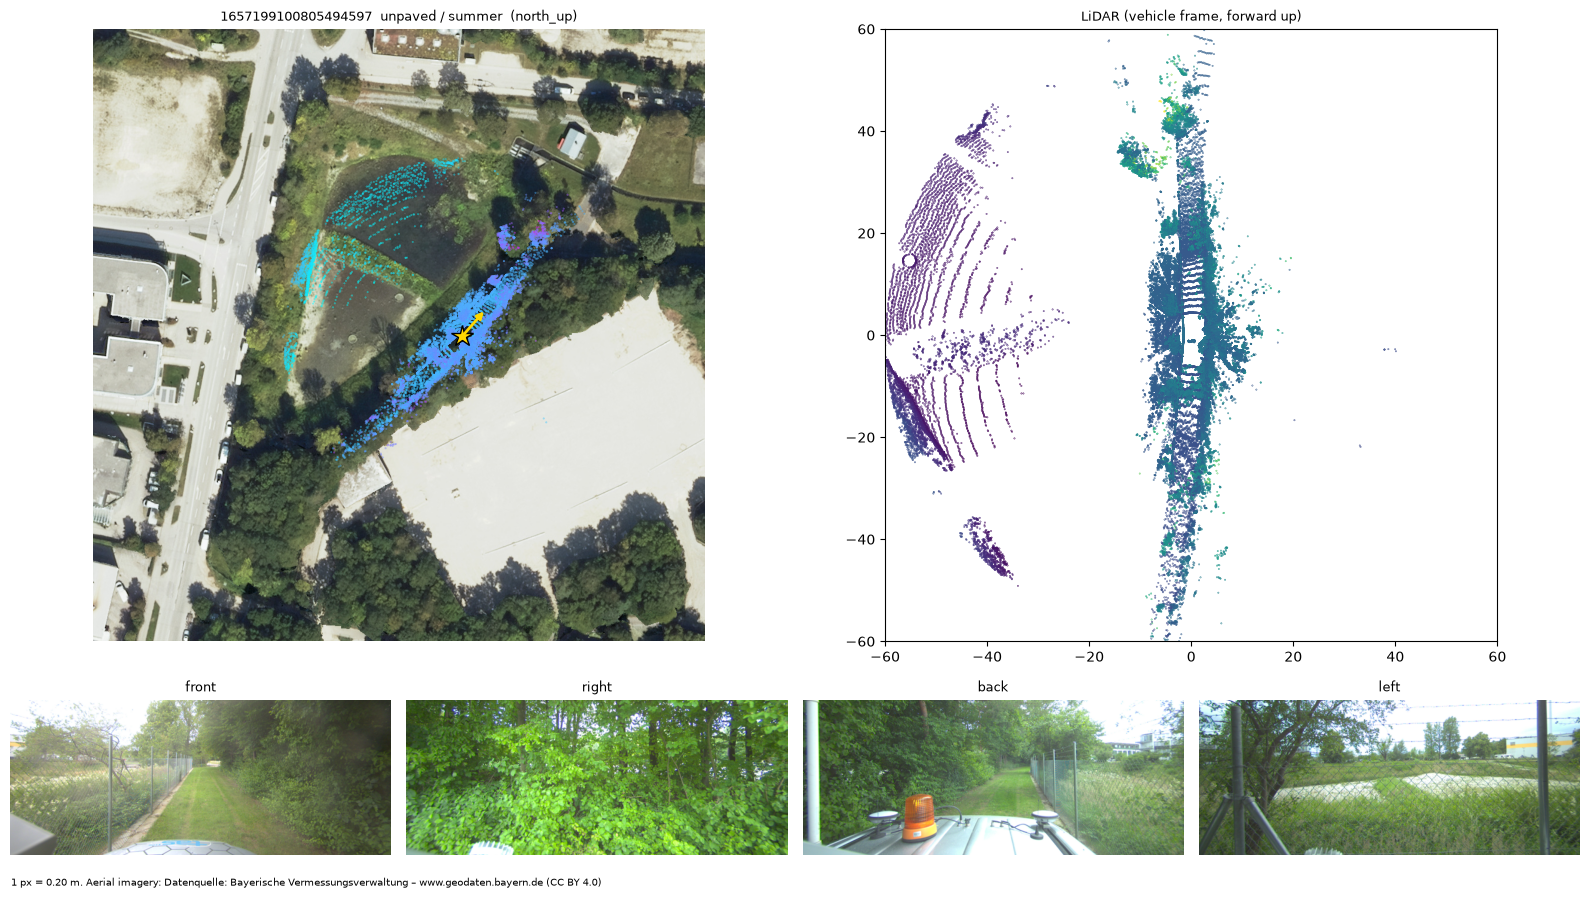

In [3]:
ds = GOOSELoc(ROOT, "test", setting="north_up", terrain="unpaved", camera_size=(250, 612))
s = ds[40]
print({k: getattr(v, "shape", v) for k, v in s.items() if k != "meta"})
print(s["meta"])
plot_sample(s);

## 3. The same scene with an IMU heading prior

The tile is rotated counter-clockwise by `heading + offset` (offset fixed per scene for
dev/test), so the vehicle faces roughly up and only the residual heading must be recovered.

tile rotation: 34.99085235595703  residual heading to predict: 6.134799480438232


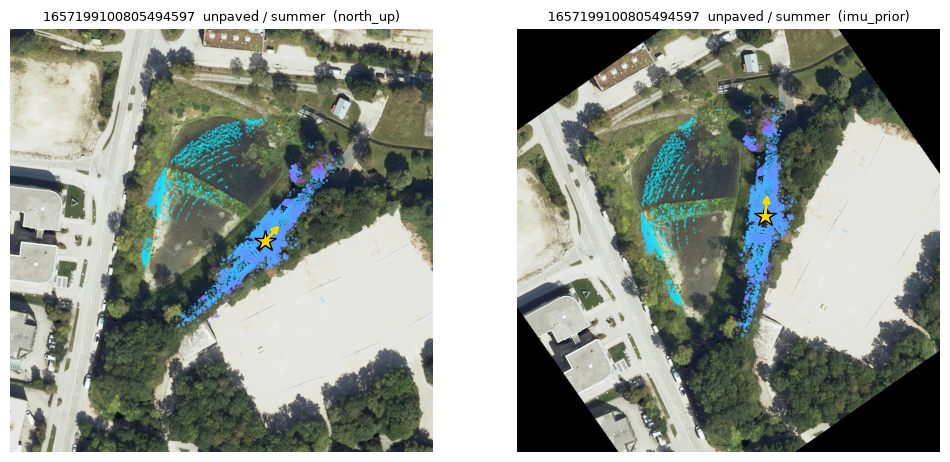

In [4]:
ds_imu = GOOSELoc(ROOT, "test", setting="imu_prior", terrain="unpaved", modalities=("aerial", "lidar"))
s_imu = ds_imu[40]
print("tile rotation:", float(s_imu["tile_rotation_deg"]), " residual heading to predict:", float(s_imu["gt_heading_deg"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plot_aerial(s, axes[0])
plot_aerial(s_imu, axes[1]);

## 4. Evaluation

Predictions are a table `scene_id, x, y, heading_deg` in the **north-up** frame.
Here: the trivial "predict the tile centre" baseline (no heading).

In [5]:
dev = select(scenes, "dev")
pred = pd.DataFrame({"scene_id": dev.scene_id, "x": 512.0, "y": 512.0})
res = evaluate(pred, "dev")
print(format_summary(res["summary"]))

group              n  loc mean  loc med   R@5m  R@10m  R@25m
------------------------------------------------------------
all             1064     38.90    40.90  0.003  0.028  0.195
paved            400     38.89    41.49  0.000  0.028  0.210
unpaved          664     38.90    40.47  0.005  0.029  0.187
winter           154     37.97    42.05  0.000  0.026  0.227
spring           304     38.73    40.23  0.000  0.026  0.191
summer           103     36.37    36.77  0.010  0.039  0.252
autumn           503     39.80    42.04  0.004  0.028  0.177


A prediction made in the rotated IMU-prior tile is mapped back with `to_north_up`:

In [6]:
from gooseloc.data.geometry import to_north_up

xy_nu, heading = to_north_up(s_imu["gt_xy"], s_imu["gt_heading_deg"], s_imu["tile_rotation_deg"])
print(xy_nu, s_imu["gt_xy_north_up"], heading, s_imu["heading_deg"])

[617.99998846 513.99998245] [618. 514.] 41.125652 41.12565


## 5. PyTorch

`GOOSELocTorch` returns float tensors; LiDAR sweeps stay variable-length lists.

In [7]:
from gooseloc.data.torch_dataset import GOOSELocTorch, make_loader

tds = GOOSELocTorch(ROOT, "train", setting="imu_prior", camera_size=(512, 1216),
                    lidar_max_points=8000, lidar_aug=True)
batch = next(iter(make_loader(tds, batch_size=4, num_workers=2)))
{k: (tuple(v.shape) if hasattr(v, "shape") else type(v).__name__) for k, v in batch.items()}

{'scene_id': 'list',
 'setting': 'list',
 'gt_xy': (4, 2),
 'gt_heading_deg': (4,),
 'tile_rotation_deg': (4,),
 'gt_xy_north_up': (4, 2),
 'heading_deg': (4,),
 'meta': 'list',
 'aerial': (4, 3, 1024, 1024),
 'cameras': (4, 4, 3, 512, 1216),
 'lidar': 'list'}